In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

import glob
import os

files = {}

for name in ["X_train", "X_test", "y_train", "y_test"]:
    matches = glob.glob(
        f"/kaggle/input/**/{name}.csv",
        recursive=True
    )
    
    if not matches:
        raise FileNotFoundError(f"{name}.csv not found!")
    
    files[name] = matches[0]

X_train = pd.read_csv(files["X_train"]).values
X_test = pd.read_csv(files["X_test"]).values

y_train = pd.read_csv(files["y_train"]).values.ravel()
y_test = pd.read_csv(files["y_test"]).values.ravel()

print("Data loaded successfully!")

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


Data loaded successfully!
X_train: (8929, 50)
X_test: (2233, 50)
y_train: (8929,)
y_test: (2233,)


In [3]:

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

print("Sigmoid function created successfully!")


Sigmoid function created successfully!


In [4]:

def compute_loss(y_true, y_pred):
    epsilon = 1e-15

    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)

    loss = -np.mean(
        y_true * np.log(y_pred) +
        (1 - y_true) * np.log(1 - y_pred)
    )

    return loss

print("Loss function created successfully!")


Loss function created successfully!


In [5]:

def compute_gradients(X, y, weights, bias):
    n = X.shape[0]

    z = np.dot(X, weights) + bias
    y_pred = sigmoid(z)

    dw = np.dot(X.T, (y_pred - y)) / n
    db = np.mean(y_pred - y)

    return dw, db


In [6]:

def gradient_descent(X, y, learning_rate=0.1, epochs=1000):

    n_samples, n_features = X.shape

    # Initialize weights and bias
    weights = np.zeros(n_features)
    bias = 0.0

    loss_history = []

    for epoch in range(epochs):

        # Calculate gradients
        dw, db = compute_gradients(
            X, y, weights, bias
        )

        # Update weights and bias
        weights -= learning_rate * dw
        bias -= learning_rate * db

        # Calculate current loss
        y_pred = sigmoid(np.dot(X, weights) + bias)
        loss = compute_loss(y, y_pred)

        loss_history.append(loss)

    return weights, bias, loss_history


print("Gradient Descent algorithm created successfully!")


Gradient Descent algorithm created successfully!


In [7]:

import time

start_time = time.time()

weights_gd, bias_gd, loss_history_gd = gradient_descent(
    X_train,
    y_train,
    learning_rate=0.1,
    epochs=1000
)

training_time_gd = time.time() - start_time

print("Training Completed!")
print("Final Training Loss:", loss_history_gd[-1])
print("Training Time:", round(training_time_gd, 4), "seconds")


Training Completed!
Final Training Loss: 0.576186356238751
Training Time: 1.0036 seconds


In [8]:

def predict(X, weights, bias, threshold=0.5):
    probabilities = sigmoid(np.dot(X, weights) + bias)

    predictions = (probabilities >= threshold).astype(int)

    return predictions


y_pred_gd = predict(
    X_test,
    weights_gd,
    bias_gd
)

print("Predictions generated successfully!")
print("First 10 Predictions:", y_pred_gd[:10])
print("First 10 Actual Values:", y_test[:10])


Predictions generated successfully!
First 10 Predictions: [0 1 1 0 0 0 0 1 1 0]
First 10 Actual Values: [0 1 0 0 1 0 0 1 1 1]


In [9]:

accuracy_gd = accuracy_score(y_test, y_pred_gd)

precision_gd = precision_score(y_test, y_pred_gd)
recall_gd = recall_score(y_test, y_pred_gd)
f1_gd = f1_score(y_test, y_pred_gd)

print("Gradient Descent Results")
print("------------------------")
print("Accuracy:", round(accuracy_gd, 4))
print("Precision:", round(precision_gd, 4))
print("Recall:", round(recall_gd, 4))
print("F1-Score:", round(f1_gd, 4))
print("Training Time:", round(training_time_gd, 4))


Gradient Descent Results
------------------------
Accuracy: 0.6946
Precision: 0.7132
Recall: 0.5945
F1-Score: 0.6485
Training Time: 1.0036


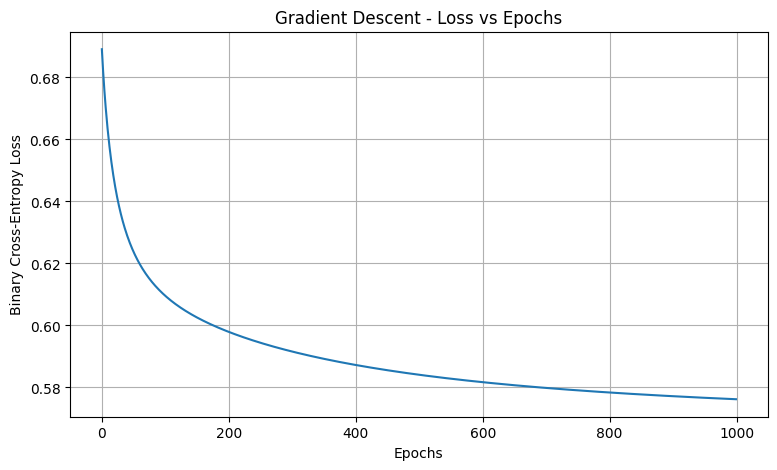

In [10]:

plt.figure(figsize=(9, 5))

plt.plot(loss_history_gd)

plt.title("Gradient Descent - Loss vs Epochs")
plt.xlabel("Epochs")
plt.ylabel("Binary Cross-Entropy Loss")

plt.grid(True)
plt.show()


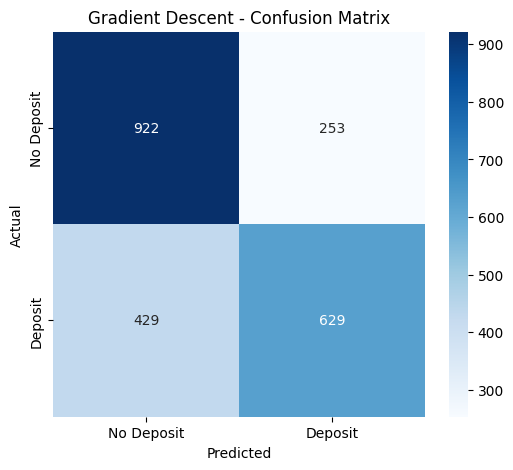

In [11]:

cm = confusion_matrix(y_test, y_pred_gd)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Deposit", "Deposit"],
    yticklabels=["No Deposit", "Deposit"]
)

plt.title("Gradient Descent - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()


## Results and Discussion

Gradient Descent achieved an accuracy of 69.46%
and an F1-score of 64.85%.

The model required 1.1572 seconds for training.

The results show that the model can identify both
classes, although its recall indicates that some
positive cases are still being missed.

These results will be used as a baseline for
comparison with the other optimization algorithms.